# SPEA2 algoritmoa (oinarrizko bertsioa)

*Strength Pareto Evolutionary Algorithm 2* (Zitzler, Laumanns eta Thiele, 2001).

**Problema:** bi helburu minimizatu

- $f_1(x_1, x_2) = x_1$
- $f_2(x_1, x_2) = x_2$

**Murriztapenak:**

- $C_1(x_1,x_2) = x_1^2 + x_2^2 - 1 - 0.1\cos\left(16\arctan\frac{x_1}{x_2}\right) \ge 0$
- $C_2(x_1,x_2) = (x_1 - 0.5)^2 + (x_2 - 0.5)^2 \le 0.5$
- $0 \le x_1, x_2 \le \pi$

Soluzio bat bideragarria ez bada, bi helburuei **10** balioa esleitzen zaie.

**NSGA-II-rekiko desberdintasunak.** Problema eta operadore genetikoak (SBX eta mutazio polinomiala) berdinak dira. SPEA2-k, ordea:

1. **Kanpoko artxibo** bat ($\bar{A}$, tamaina finkoa $\bar{N}$) erabiltzen du aurkitutako soluzio ez-menderatuak gordetzeko.
2. Fronteen ordez, **egokitasun** bakar bat kalkulatzen du: $F(i) = H(i) + D(i)$ (indarra + dentsitatea).
3. Artxiboan gehiegi daudenean, **trunkatze**-operadore batek auzokide hurbilenak dituztenak kentzen ditu.
4. Gurasoak **artxibotik bakarrik** hautatzen dira.

## 1. Liburutegiak eta parametroak

In [9]:
import math
import random
import matplotlib.pyplot as plt

POP_TAMAINA = 100        # Populazioaren tamaina (N)
ARTXIBO_TAMAINA = 100    # Artxiboaren tamaina (N̄)
BELAUNALDIAK = 200       # Belaunaldi kopurua
GURUTZAKETA_PROB = 0.9   # Gurutzaketa probabilitatea
MUTAZIO_PROB = 0.5       # Mutazio probabilitatea (aldagai bakoitzeko: 1/n, n=2)
ETA_C = 20               # SBX gurutzaketaren banaketa-indizea
ETA_M = 20               # Mutazio polinomialaren banaketa-indizea
BEHE_MUGA = 0.0
GOI_MUGA = math.pi
EZ_BIDERAGARRIA = 10.0   # Soluzio ez bideragarriei esleitzen zaien balioa
HAZIA = random.randrange(1_000_000)  # Ausazko hazia (finkatu, adib. 1, emaitza errepikatzeko)
COS_KOEF = 0.1          # C1 murriztapeneko cos-aren koefizientea (TNK problema)

print(f"Hazia: {HAZIA}")

## 2. Problema: helburu funtzioak eta murriztapenak

`atan2(x1, x2)` erabiltzen da: $x_2 > 0$ denean $\arctan(x_1/x_2)$-ren berdina da, eta $x_2 = 0$ kasuan zatiketa zeroz saihesten du.

In [10]:
def c1(x1, x2):
    # atan2(x1, x2) = arctan(x1/x2) x2 > 0 denean, eta x2 = 0 kasuan ere ondo dabil
    return x1 ** 2 + x2 ** 2 - 1 - COS_KOEF * math.cos(16 * math.atan2(x1, x2))


def c2(x1, x2):
    return (x1 - 0.5) ** 2 + (x2 - 0.5) ** 2


def bideragarria(x):
    x1, x2 = x
    return c1(x1, x2) >= 0 and c2(x1, x2) <= 0.5


def ebaluatu(x):
    """Helburu funtzioen balioak itzultzen ditu: (f1, f2)."""
    if not bideragarria(x):
        return (EZ_BIDERAGARRIA, EZ_BIDERAGARRIA)
    return (x[0], x[1])

## 3. Dominantzia eta distantzia

$a$-k $b$ menderatzen du helburu guztietan $a$ ez bada okerragoa eta gutxienez batean hobea bada. Dentsitatea eta trunkatzea kalkulatzeko, helburuen espazioko distantzia euklidearra erabiltzen da.

In [11]:
def menderatzen_du(a, b):
    """True, a-k b menderatzen badu (minimizazioa)."""
    hobea_edo_berdina = all(ai <= bi for ai, bi in zip(a, b))
    hobea_bat = any(ai < bi for ai, bi in zip(a, b))
    return hobea_edo_berdina and hobea_bat


def distantzia(a, b):
    """Distantzia euklidearra helburuen espazioan."""
    return math.dist(a, b)

## 4. Egokitasuna: $F(i) = H(i) + D(i)$

$P_t \cup \bar{A}_t$ multzo osoan kalkulatzen da (txikiagoa = hobea):

- **Indarra** $S(i) = |\{j : i \succ j\}|$: $i$-k menderatzen dituen soluzio kopurua.
- **Egokitasun gordina** $H(i) = \sum_{j \succ i} S(j)$: $i$ menderatzen dutenen indarren batura. Ez-menderatuek $H(i) = 0$ dute.
- **Dentsitatea** $D(i) = \dfrac{1}{\sigma_i^k + 2}$, non $\sigma_i^k$ $i$-tik $k$. auzokide hurbilenera dagoen distantzia den eta $k = \lfloor\sqrt{N + \bar{N}}\rfloor$ (populazioaren eta artxiboaren tamainen baturaren erro karratua; N = N̄ = 100 denean, $k = 14$). $D(i) \in (0, 0.5]$, beraz $F(i) < 1 \iff i$ ez-menderatua.

$H$-k konbergentzia bultzatzen du; $D$-k, berriz, $R$ berdina dutenen artean eremu hutsagoetakoak lehenesten ditu (dibertsitatea).

In [12]:
def egokitasuna(helburuak):
    """
    Soluzio bakoitzaren egokitasuna (txikiagoa = hobea) eta distantzia-matrizea.
    F(i) < 1  <=>  i ez-menderatua da.
    """
    n = len(helburuak)

    # Indarra S(i): i-k menderatzen dituen soluzio kopurua
    menderatzaileak = [[] for _ in range(n)]   # menderatzaileak[i]: i menderatzen dutenak
    indarra = [0] * n
    for i in range(n):
        for j in range(n):
            if i != j and menderatzen_du(helburuak[i], helburuak[j]):
                indarra[i] += 1
                menderatzaileak[j].append(i)

    # Egokitasun gordina H(i): i menderatzen dutenen indarren batura
    gordina = [sum(indarra[j] for j in menderatzaileak[i]) for i in range(n)]

    # Dentsitatea D(i) = 1 / (sigma_i^k + 2), k = sqrt(N + N̄)
    dist = [[distantzia(helburuak[i], helburuak[j]) for j in range(n)] for i in range(n)]
    k = int(math.sqrt(POP_TAMAINA + ARTXIBO_TAMAINA))
    k = min(max(k, 1), n - 1)
    dentsitatea = []
    for i in range(n):
        auzokideak = sorted(dist[i][j] for j in range(n) if j != i)
        dentsitatea.append(1.0 / (auzokideak[k - 1] + 2.0))

    F = [gordina[i] + dentsitatea[i] for i in range(n)]
    return F, dist

## 5. Ingurune-hautaketa (artxiboa eguneratu)

1. Ez-menderatu guztiak ($F < 1$) $\bar{A}_{t+1}$-era kopiatu.
2. $|\bar{A}_{t+1}| > \bar{N}$ bada: **trunkatu**. Behin eta berriz, auzokide hurbilenarekiko distantzia txikiena duen soluzioa kendu (berdinketan, 2. auzokidea begiratu, eta abar: distantzia-zerrenda ordenatuen hiztegi-ordena). Horrela, muturrak eta dibertsitatea mantentzen dira.
3. $|\bar{A}_{t+1}| < \bar{N}$ bada: $F$ txikiena duten menderatuekin bete.

In [14]:
def trunkatu(hautagaiak, dist, tamaina):
    """
    Ez-menderatu gehiegi daudenean: auzokide hurbilena (berdinketan, 2. hurbilena,
    etab.) duen soluzioa kendu behin eta berriz, `tamaina` geratu arte.
    """
    geratzen = list(hautagaiak)
    # Soluzio bakoitzeko gainerakoekiko distantziak, txikienetik handienera
    auzokideak = {i: sorted(dist[i][j] for j in geratzen if j != i) for i in geratzen}
    while len(geratzen) > tamaina:
        # Distantzia-zerrendak hiztegi-ordenan alderatu: txikiena da kentzekoa
        kendu = min(geratzen, key=lambda i: auzokideak[i])
        geratzen.remove(kendu)
        del auzokideak[kendu]
        for i in geratzen:
            auzokideak[i].remove(dist[i][kendu])
    return geratzen


def ingurune_hautaketa(populazioa, helburuak, F, dist):
    """Ez-menderatuak (F < 1) artxibora; gero trunkatu edo menderatuekin bete."""
    ez_menderatuak = [i for i in range(len(F)) if F[i] < 1]
    if len(ez_menderatuak) > ARTXIBO_TAMAINA:
        hautatuak = trunkatu(ez_menderatuak, dist, ARTXIBO_TAMAINA)
    else:
        # Gutxiegi: F txikiena duten menderatuekin bete
        hautatuak = sorted(range(len(F)), key=lambda i: F[i])[:ARTXIBO_TAMAINA]
    return ([populazioa[i] for i in hautatuak],
            [helburuak[i] for i in hautatuak],
            [F[i] for i in hautatuak])

## 6. Operadore genetikoak

- **Txapelketa bitarra** (itzulerarekin) artxiboan: $F$ txikiena duenak irabazten du.
- **SBX gurutzaketa** eta **mutazio polinomiala**, NSGA-II-n bezala.

In [15]:
def txapelketa_bitarra(F):
    """Bi indibiduo ausaz hartu (itzulerarekin) eta F txikiena duena itzuli."""
    a = random.randrange(len(F))
    b = random.randrange(len(F))
    return a if F[a] <= F[b] else b


def mugatu(v):
    return min(max(v, BEHE_MUGA), GOI_MUGA)


def sbx_gurutzaketa(g1, g2):
    """Simulated Binary Crossover (SBX)."""
    if random.random() > GURUTZAKETA_PROB:
        return g1[:], g2[:]
    s1, s2 = [], []
    for x1, x2 in zip(g1, g2):
        u = random.random()
        if u <= 0.5:
            beta = (2 * u) ** (1 / (ETA_C + 1))
        else:
            beta = (1 / (2 * (1 - u))) ** (1 / (ETA_C + 1))
        s1.append(mugatu(0.5 * ((1 + beta) * x1 + (1 - beta) * x2)))
        s2.append(mugatu(0.5 * ((1 - beta) * x1 + (1 + beta) * x2)))
    return s1, s2


def mutazio_polinomiala(x):
    """Mutazio polinomiala, aldagai bakoitzean MUTAZIO_PROB probabilitatearekin."""
    y = x[:]
    tartea = GOI_MUGA - BEHE_MUGA
    for i in range(len(y)):
        if random.random() < MUTAZIO_PROB:
            u = random.random()
            if u < 0.5:
                delta = (2 * u) ** (1 / (ETA_M + 1)) - 1
            else:
                delta = 1 - (2 * (1 - u)) ** (1 / (ETA_M + 1))
            y[i] = mugatu(y[i] + delta * tartea)
    return y


def ondorengoak_sortu(artxiboa, F):
    """Artxibotik txapelketaz gurasoak hartu eta N ondorengo sortu."""
    ondorengoak = []
    while len(ondorengoak) < POP_TAMAINA:
        g1 = artxiboa[txapelketa_bitarra(F)]
        g2 = artxiboa[txapelketa_bitarra(F)]
        s1, s2 = sbx_gurutzaketa(g1, g2)
        ondorengoak.append(mutazio_polinomiala(s1))
        if len(ondorengoak) < POP_TAMAINA:
            ondorengoak.append(mutazio_polinomiala(s2))
    return ondorengoak

## 7. SPEA2 algoritmo nagusia

1. $P_0$ ausaz sortu; $\bar{A}_0 = \emptyset$.
2. $P_t \cup \bar{A}_t$-ren egokitasuna kalkulatu.
3. Ingurune-hautaketa: $\bar{A}_{t+1}$.
4. $t = T$ bada, amaitu: emaitza $\bar{A}_{t+1}$-eko ez-menderatuak.
5. Gurasoak $\bar{A}_{t+1}$-etik txapelketaz hautatu.
6. Gurutzaketa eta mutazioa: $P_{t+1}$. $t \leftarrow t+1$ eta 2. urratsera.

`historia` zerrenda bat ematen bada, belaunaldi bakoitzeko artxiboa gordetzen da (bilakaera irudikatzeko).

In [16]:
def spea2(historia=None, isilik=False):
    """
    historia: zerrenda bat ematen bada, belaunaldi bakoitzeko artxiboa
    (A, A_helb) gordetzen da bertan (0. elementua = hasierako populaziotik
    lortutako artxiboa).
    """
    random.seed(HAZIA)

    # 1. Hasierako populazioa ausaz sortu eta ebaluatu; artxiboa hutsik
    P = [[random.uniform(BEHE_MUGA, GOI_MUGA) for _ in range(2)]
         for _ in range(POP_TAMAINA)]
    P_helb = [ebaluatu(x) for x in P]
    A, A_helb = [], []

    for belaunaldia in range(BELAUNALDIAK + 1):
        # 2. Egokitasuna P ∪ A osoan kalkulatu
        R, R_helb = P + A, P_helb + A_helb
        F, dist = egokitasuna(R_helb)

        # 3. Ingurune-hautaketa: hurrengo artxiboa
        A, A_helb, A_F = ingurune_hautaketa(R, R_helb, F, dist)
        if historia is not None:
            historia.append(([x[:] for x in A], list(A_helb)))

        if not isilik and belaunaldia > 0 and belaunaldia % 20 == 0:
            bider = sum(1 for f in A_helb if f[0] != EZ_BIDERAGARRIA)
            ez_mend = sum(1 for f in A_F if f < 1)
            print(f"Belaunaldia {belaunaldia:4d} | artxiboan bideragarriak: {bider:3d} "
                  f"| ez-menderatuak: {ez_mend:3d}")

        # 4. Amaiera-irizpidea
        if belaunaldia == BELAUNALDIAK:
            break

        # 5-6. Gurasoen hautaketa (artxibotik) eta aldakuntza: P berria
        P = ondorengoak_sortu(A, A_F)
        P_helb = [ebaluatu(x) for x in P]

    # 7. Azken Pareto frontea: artxiboko soluzio ez-menderatu bideragarriak
    pareto = [(A[i], A_helb[i]) for i in range(len(A))
              if A_F[i] < 1 and A_helb[i][0] != EZ_BIDERAGARRIA]
    pareto.sort(key=lambda s: s[1][0])
    return pareto

## 8. Exekuzioa

In [17]:
historia = []
pareto = spea2(historia=historia)
print(f"\nPareto fronteko soluzio kopurua: {len(pareto)}")
for x, f in pareto[:10]:
    print(f"  x = ({x[0]:.4f}, {x[1]:.4f})  ->  f = ({f[0]:.4f}, {f[1]:.4f})")
if len(pareto) > 10:
    print("  ...")

Belaunaldia   20 | artxiboan bideragarriak: 100 | ez-menderatuak:  97
Belaunaldia   40 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia   60 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia   80 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  100 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  120 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  140 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  160 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  180 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  200 | artxiboan bideragarriak: 100 | ez-menderatuak: 100

Pareto fronteko soluzio kopurua: 100
  x = (0.0431, 1.0392)  ->  f = (0.0431, 1.0392)
  x = (0.0504, 1.0342)  ->  f = (0.0504, 1.0342)
  x = (0.0578, 1.0300)  ->  f = (0.0578, 1.0300)
  x = (0.0659, 1.0251)  ->  f = (0.0659, 1.0251)
  x = (0.0751, 1.0178)  ->  f = (0.0751, 1.0178)
  x = (0.0836, 1.

## 9. Pareto frontea irudikatu

Grisez, eskualde bideragarria; urdinez, SPEA2-k lortutako frontea.

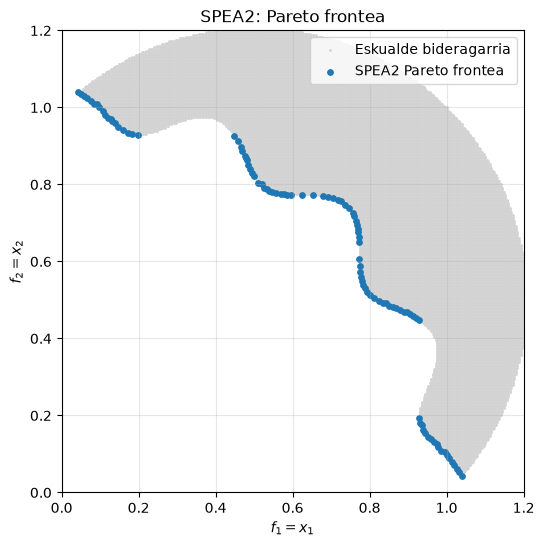

In [18]:
# Eskualde bideragarria marraztu (sare fin bat ebaluatuz)
sarea = [i * 1.2 / 300 for i in range(301)]
bx, by = [], []
for a in sarea:
    for b in sarea:
        if bideragarria((a, b)):
            bx.append(a)
            by.append(b)

f1 = [s[1][0] for s in pareto]
f2 = [s[1][1] for s in pareto]

plt.figure(figsize=(6, 6))
plt.scatter(bx, by, s=1, c="lightgray", label="Eskualde bideragarria")
plt.scatter(f1, f2, s=15, c="tab:blue", label="SPEA2 Pareto frontea")
plt.xlabel("$f_1 = x_1$")
plt.ylabel("$f_2 = x_2$")
plt.xlim(0, 1.2)
plt.ylim(0, 1.2)
plt.gca().set_aspect("equal")
plt.grid(alpha=0.3)
plt.legend(loc="upper right")
plt.title("SPEA2: Pareto frontea")
plt.show()

### Artxiboaren bilakaera

Artxiboa belaunaldi batzuetan: hasieran soluzio gutxi daude frontetik gertu; gero artxiboa frontean zehar hedatzen da.

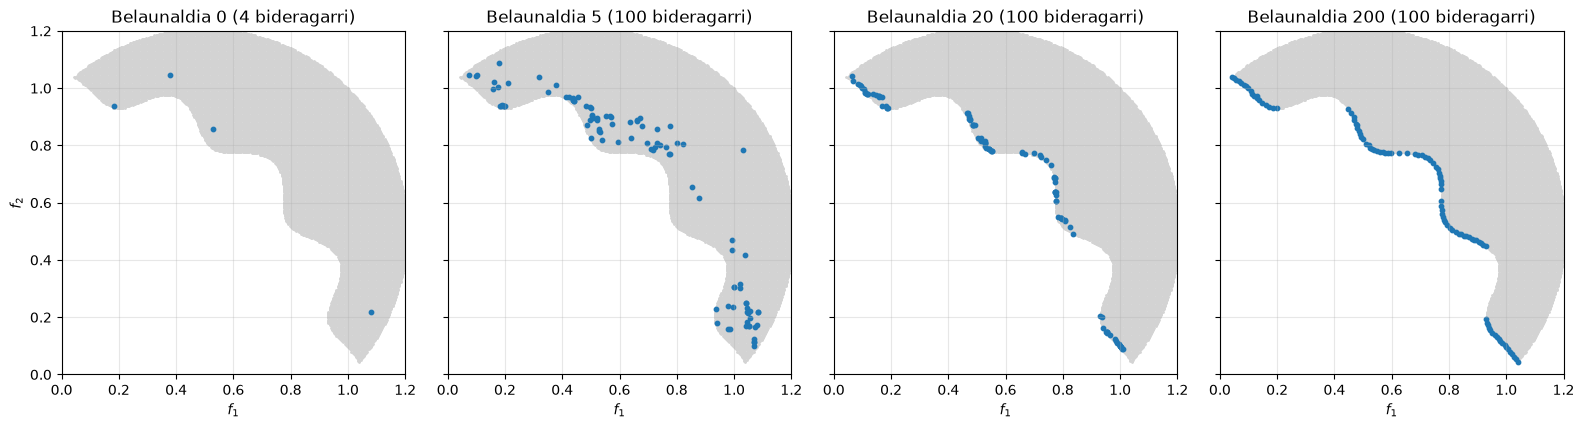

In [19]:
erakutsi = [0, 5, 20, len(historia) - 1]
fig, ardatzak = plt.subplots(1, len(erakutsi), figsize=(4 * len(erakutsi), 4), sharey=True)
for ax, t in zip(ardatzak, erakutsi):
    A_helb = [f for f in historia[t][1] if f[0] != EZ_BIDERAGARRIA]
    ax.scatter(bx, by, s=1, c="lightgray")
    ax.scatter([f[0] for f in A_helb], [f[1] for f in A_helb], s=10, c="tab:blue")
    ax.set_xlim(0, 1.2)
    ax.set_ylim(0, 1.2)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_title(f"Belaunaldia {t} ({len(A_helb)} bideragarri)")
    ax.set_xlabel("$f_1$")
ardatzak[0].set_ylabel("$f_2$")
plt.tight_layout()
plt.show()

## 10. Konparaketa NSGA-II-rekin

Parametro eta hazi berdinekin (goian ausaz aukeratutakoa) exekutatzen da `nsga2.py` (N = 100, 200 belaunaldi) eta bi fronteak alderatzen dira `metrikak.py`-ko metrikekin:

- **Hiperbolumena (HV)**: frontea menderatzen duen azalera $(1.2, 1.2)$ erreferentzia-punturaino, benetako frontearenarekiko ehunekotan. Handiagoa = hobea.
- **IGD** (*Inverted Generational Distance*): benetako fronteko puntu bakoitzetik lortutako fronteko puntu hurbilenera dagoen batez besteko distantzia. Txikiagoa = hobea.
- **Tartekatzea (spacing)**: fronteko auzokide hurbilenen arteko distantzien desbideratze estandarra. Txikiagoa = banaketa uniformeagoa.

Benetako frontea sare fin batean kalkulatzen da: $x_1$ bakoitzeko $x_2$ bideragarri txikiena, eta horietatik ez-menderatuak.

In [20]:
import time
import statistics
import nsga2
import metrikak

ERREF_PUNTUA = (1.2, 1.2)


def benetako_frontea(n=1500, muga=1.25):
    ertza = []
    for i in range(n + 1):
        a = muga * i / n
        for j in range(n + 1):
            b = muga * j / n
            if bideragarria((a, b)):
                ertza.append((a, b))
                break
    frontea, onena = [], float("inf")
    for a, b in sorted(ertza):
        if b < onena:
            frontea.append((a, b))
            onena = b
    return frontea


def tartekatzea(puntuak):
    if len(puntuak) < 2:
        return math.nan
    d = [min(math.dist(p, q) for q in puntuak if q is not p) for p in puntuak]
    return statistics.pstdev(d)


erref_frontea = benetako_frontea()
hv_optimoa = metrikak.hiperbolumena(erref_frontea, ERREF_PUNTUA)

# NSGA-II parametro berdinekin
for izena in ["POP_TAMAINA", "BELAUNALDIAK", "GURUTZAKETA_PROB", "MUTAZIO_PROB",
              "ETA_C", "ETA_M", "HAZIA"]:
    setattr(nsga2, izena, globals()[izena])

hasiera = time.perf_counter()
pareto_nsga2 = nsga2.nsga2(isilik=True)
denbora_nsga2 = time.perf_counter() - hasiera

hasiera = time.perf_counter()
pareto_spea2 = spea2()
denbora_spea2 = time.perf_counter() - hasiera

emaitzak = {}
for izena, frontea, denbora in [("NSGA-II", pareto_nsga2, denbora_nsga2),
                                 ("SPEA2", pareto_spea2, denbora_spea2)]:
    F = [f for _, f in frontea]
    emaitzak[izena] = F
    print(f"{izena:8s} | soluzioak: {len(F):3d} "
          f"| HV: {100 * metrikak.hiperbolumena(F, ERREF_PUNTUA) / hv_optimoa:6.2f} % "
          f"| IGD: {metrikak.igd(F, erref_frontea):.5f} "
          f"| tartekatzea: {tartekatzea(F):.5f} "
          f"| denbora: {denbora:5.1f} s")

Belaunaldia   20 | artxiboan bideragarriak: 100 | ez-menderatuak:  97
Belaunaldia   40 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia   60 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia   80 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  100 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  120 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  140 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  160 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  180 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
Belaunaldia  200 | artxiboan bideragarriak: 100 | ez-menderatuak: 100
NSGA-II  | soluzioak: 100 | HV:  99.38 % | IGD: 0.00421 | tartekatzea: 0.00549 | denbora:  12.8 s
SPEA2    | soluzioak: 100 | HV:  99.53 % | IGD: 0.00335 | tartekatzea: 0.00337 | denbora:   7.3 s


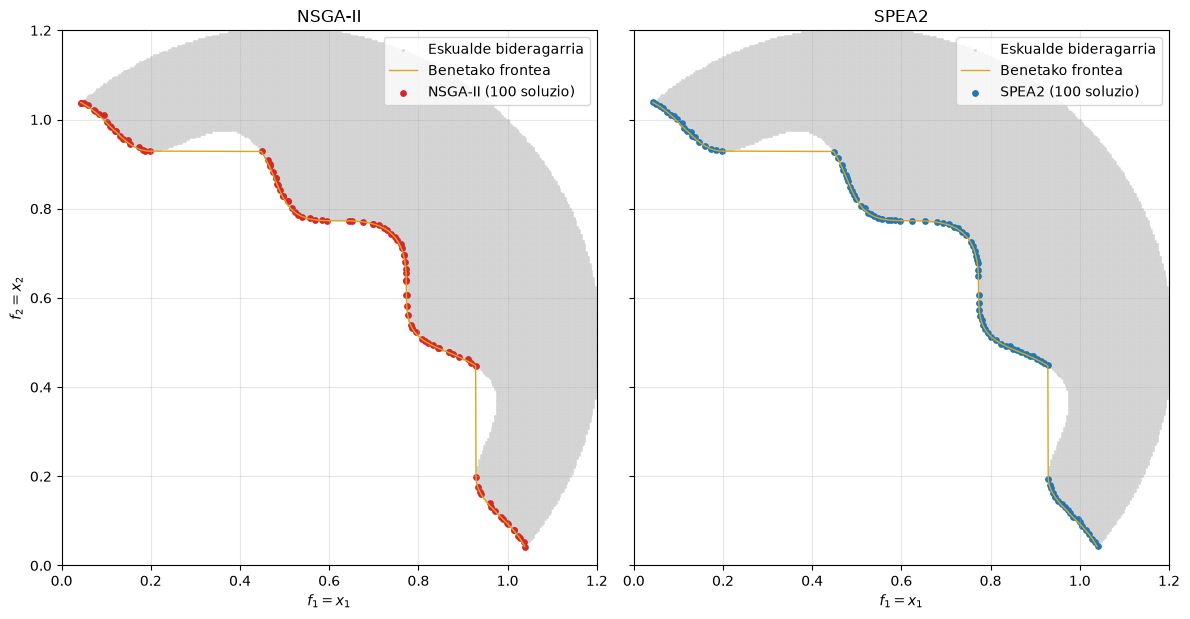

In [21]:
fig, ardatzak = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
koloreak = {"NSGA-II": "tab:red", "SPEA2": "tab:blue"}
for ax, (izena, F) in zip(ardatzak, emaitzak.items()):
    ax.scatter(bx, by, s=1, c="lightgray", label="Eskualde bideragarria")
    ax.plot([p[0] for p in erref_frontea], [p[1] for p in erref_frontea],
            c="goldenrod", lw=1, label="Benetako frontea")
    ax.scatter([f[0] for f in F], [f[1] for f in F], s=15, c=koloreak[izena],
               label=f"{izena} ({len(F)} soluzio)")
    ax.set_xlim(0, 1.2)
    ax.set_ylim(0, 1.2)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_xlabel("$f_1 = x_1$")
    ax.legend(loc="upper right")
    ax.set_title(izena)
ardatzak[0].set_ylabel("$f_2 = x_2$")
plt.tight_layout()
plt.show()

**Oharrak.**

- Biek erabiltzen dituzte operadore genetiko berdinak; aldea **hautaketan** dago: NSGA-II-k fronteak + pilaketa-distantzia, SPEA2-k indarra + $k$-NN dentsitatea + trunkatzea.
- SPEA2-ren trunkatzeak soluzioak modu uniformeagoan banatzen ditu normalean (tartekatze txikiagoa). Teorian garestiagoa da ($O(M^3)$ okerrenean, $M = N + \bar{N}$), baina praktikan artxiboa ia beti ez-menderatuz beteta dagoenez, kostu nagusia dominantzia-konparaketak dira, NSGA-II-n bezala.
- Problema honetan frontea etena da (cos-aren uhinengatik); bi algoritmoek tarte bideragarrietan bakarrik kokatzen dituzte soluzioak.